# Stage 3 — A CFD surrogate from AirfRANS

**Vamsi Gudipati**

This notebook replaces the thin-airfoil law with a neural-network surrogate trained on the AirfRANS coefficient table: a multilayer perceptron that maps the Reynolds number, the angle of attack and the three NACA four-digit parameters to the lift and drag coefficients. I train it with early stopping on the training split, score it on the test split, and added a training animation and seven exercises (architecture, dropping the Reynolds number, single-output models, scarce data, extrapolation in Reynolds number and angle, the five-digit family, and an ensemble), plus an evaluation of the surrogate file that the next stage uses.

Cell numbers quoted inside this notebook count the first cell below this header as cell 0.

Portfolio page: https://vamsigudipati.github.io/airfoil-cfd-surrogate-drl.html


# Stage 3 — Building a CFD Surrogate with AirfRANS

In the previous stage we controlled a simplified two-dimensional airfoil model with deep reinforcement learning.

We now take one step toward **CFD-informed control**.

Instead of using a simple analytical relation such as

$$
C_L = 2\pi\alpha,
$$

we will construct a neural-network surrogate from high-fidelity RANS simulations contained in the **AirfRANS** dataset.

For this first surrogate we deliberately focus on a low-dimensional aerodynamic map:

$$
\boxed{
(Re,\alpha,m,p,t)
\longrightarrow
(C_L,C_D)
}
$$

where

- $Re$ is the Reynolds number,
- $\alpha$ is the angle of attack,
- $m,p,t$ describe a NACA four-digit airfoil,
- $C_L$ and $C_D$ are obtained from CFD.

This is much cheaper than predicting the complete velocity and pressure fields, but it already gives us a CFD-informed model that can later be inserted inside a Gymnasium environment.

The final objective is

$$
\text{AirfRANS CFD}
\rightarrow
\text{MLP surrogate}
\rightarrow
\widehat C_L,\widehat C_D
\rightarrow
\text{DRL}.
$$

## 1. Why a surrogate?

A DRL algorithm may require tens or hundreds of thousands of interactions with its environment.

Calling a full RANS solver at every interaction would be prohibitively expensive.

Instead, we first evaluate the CFD database offline and train a neural approximation

$$
\mathcal{N}_\theta:
(Re,\alpha,m,p,t)
\mapsto
(C_L,C_D).
$$

Once trained, one surrogate evaluation takes a tiny fraction of the time required by a CFD simulation.

This introduces an important workflow in modern computational mechanics:

$$
\boxed{
\text{high-fidelity solver}
\rightarrow
\text{database}
\rightarrow
\text{surrogate}
\rightarrow
\text{control/optimization}
}
$$

The surrogate does **not** replace CFD as a source of physical truth. It replaces repeated CFD evaluations inside a computationally intensive outer loop.

## 2. About AirfRANS

AirfRANS contains 1000 incompressible two-dimensional RANS simulations of NACA four- and five-digit airfoils.

The database covers approximately

$$
2\times10^6 \le Re \le 6\times10^6
$$

and

$$
-5^\circ \le \alpha \le 15^\circ.
$$

The simulations were generated with OpenFOAM and include the velocity, pressure and turbulent-viscosity fields. The AirfRANS Python library can also compute aerodynamic force coefficients directly from the reference CFD solution.

In this notebook we restrict ourselves to **four-digit NACA airfoils**. This gives us a simple fixed-size geometry representation:

$$
(m,p,t).
$$

AirfRANS uses continuously sampled values of these parameters, rather than only classical integer NACA designations.

### Important practical point

The full preprocessed AirfRANS database is large. For teaching, the recommended workflow is:

1. download AirfRANS once;
2. extract one small table containing $Re,\alpha,m,p,t,C_L,C_D$;
3. save that table as a CSV;
4. share the CSV.

After the CSV has been generated, the neural-network part of this notebook is lightweight.

## 3. Install the libraries

`airfrans` is required only for the initial extraction of CFD coefficients. TensorFlow/Keras is used for the multilayer perceptron.

In [1]:
%pip -q install airfrans scikit-learn pandas joblib

Note: you may need to restart the kernel to use updated packages.


## 4. Imports and reproducibility

In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

SEED = 7
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Part A — Preparing the CFD coefficient database

This part has to be executed only once. If `airfrans_4digit_coefficients.csv` is already available, you can skip directly to **Part B**.

## 5. Download AirfRANS

The official Python interface provides `airfrans.dataset.download(...)` for downloading the preprocessed dataset. Because the database is large, downloading it during every classroom session is not recommended. Set `DOWNLOAD_DATASET = True` only if AirfRANS is not already available locally.

In [3]:
import airfrans as af



DATA_PARENT = Path("/path/to/AirfRANS")
DATA_ROOT = DATA_PARENT / "Dataset"

DOWNLOAD_DATASET = False

if DOWNLOAD_DATASET:
    af.dataset.download(
        root=str(DATA_PARENT),
        file_name="Dataset",
        unzip=True,
        OpenFOAM=False,
    )

print("Expected AirfRANS directory:", DATA_ROOT)
print("Dataset found:", DATA_ROOT.exists())

Expected AirfRANS directory: /path/to/AirfRANS/Dataset
Dataset found: False


## 6. Read the official AirfRANS train/test split

AirfRANS provides several predefined machine-learning tasks. We begin with the **full-data interpolation task**, which contains an official training set and an independent test set drawn from the same distribution. We retain only simulations belonging to the four-digit NACA family.

In [4]:
def geometry_parameters_from_name(name):
    parts = name.split("_")
    return [float(value) for value in parts[4:]]


def is_four_digit_case(name):
    return len(geometry_parameters_from_name(name)) == 3


manifest_file = DATA_ROOT / "manifest.json"

if manifest_file.exists():
    with open(manifest_file, "r") as f:
        manifest = json.load(f)

    train_names = [
        name for name in manifest["full_train"]
        if is_four_digit_case(name)
    ]

    test_names = [
        name for name in manifest["full_test"]
        if is_four_digit_case(name)
    ]

    print("Four-digit training simulations:", len(train_names))
    print("Four-digit test simulations:    ", len(test_names))
else:
    print("manifest.json was not found. This is expected if you are using a pre-generated CSV.")

manifest.json was not found. This is expected if you are using a pre-generated CSV.


## 7. Extract $Re$, geometry, $C_L$, and $C_D$

For each CFD case we need only seven numbers:

$$
(Re,\alpha,m,p,t,C_L,C_D).
$$

The AirfRANS `Simulation` class gives access to the inlet velocity and angle of attack and can compute the force coefficients from the stored reference CFD fields.

The database was generated using approximately

$$
\nu = 1.56\times 10^{-5}\ {\rm m^2/s}
$$

and a unit chord, so

$$
Re = \frac{U_\infty}{\nu}.
$$

The force-coefficient method returns drag first and lift second.

In [5]:
NU_DATASET = 1.56e-5


def extract_one_case(name, split, root=DATA_ROOT):
    simulation = af.Simulation(root=str(root), name=name)

    geometry = geometry_parameters_from_name(name)
    if len(geometry) != 3:
        raise ValueError("This notebook uses only four-digit-family cases.")

    m, p, t = geometry

    reynolds = simulation.inlet_velocity / NU_DATASET
    alpha_deg = np.rad2deg(simulation.angle_of_attack)

    force_coefficients = simulation.force_coefficient(reference=True)
    cd = float(force_coefficients[0][0])
    cl = float(force_coefficients[1][0])

    return {
        "name": name,
        "split": split,
        "Re": reynolds,
        "Re_M": reynolds / 1.0e6,
        "alpha_deg": alpha_deg,
        "m": m,
        "p": p,
        "t": t,
        "CL": cl,
        "CD": cd,
    }

## 8. Build and cache the lightweight dataset

The following cell may take some time because it opens each CFD simulation once. After that, the full aerodynamic surrogate problem is contained in a very small CSV file.

In [6]:
COEFFICIENT_FILE = Path("../data/airfrans_4digit_coefficients.csv")
BUILD_COEFFICIENT_FILE = False

if BUILD_COEFFICIENT_FILE:
    if not manifest_file.exists():
        raise FileNotFoundError(
            "AirfRANS was not found. Download the dataset or provide the coefficient CSV."
        )

    records = []

    for i, name in enumerate(train_names):
        records.append(extract_one_case(name, split="train"))
        if (i + 1) % 25 == 0:
            print(f"Processed {i + 1}/{len(train_names)} training cases")

    for i, name in enumerate(test_names):
        records.append(extract_one_case(name, split="test"))
        if (i + 1) % 25 == 0:
            print(f"Processed {i + 1}/{len(test_names)} test cases")

    coefficient_df = pd.DataFrame(records)
    coefficient_df.to_csv(COEFFICIENT_FILE, index=False)

    print("Saved:", COEFFICIENT_FILE)
    print("Rows:", len(coefficient_df))
else:
    print(
        "Coefficient extraction skipped. Use an existing CSV or set BUILD_COEFFICIENT_FILE = True."
    )

Coefficient extraction skipped. Use an existing CSV or set BUILD_COEFFICIENT_FILE = True.


# Part B — Training the aerodynamic surrogate

## 9. Load the coefficient table

If the file is stored elsewhere, change `COEFFICIENT_FILE`.

In [7]:
COEFFICIENT_FILE = Path("../data/airfrans_4digit_coefficients.csv")

if not COEFFICIENT_FILE.exists():
    raise FileNotFoundError(
        f"{COEFFICIENT_FILE} was not found.\n"
        "Either generate it in Part A or upload the provided CSV."
    )

df = pd.read_csv(COEFFICIENT_FILE)
print("Number of simulations:", len(df))
print()
print(df.head())

Number of simulations: 489

                                             name  split            Re  \
0  airFoil2D_SST_58.831_-3.563_2.815_4.916_10.078  train  3.771218e+06   
1   airFoil2D_SST_43.327_8.905_4.236_6.511_10.744  train  2.777372e+06   
2    airFoil2D_SST_46.246_9.78_3.769_2.353_17.745  train  2.964487e+06   
3  airFoil2D_SST_67.481_-1.259_5.136_2.438_18.882  train  4.325705e+06   
4     airFoil2D_SST_46.0_-0.095_2.322_1.874_16.58  train  2.948718e+06   

       Re_M  alpha_deg      m      p       t        CL        CD  
0  3.771218     -3.563  2.815  4.916  10.078 -0.061631  0.008585  
1  2.777372      8.905  4.236  6.511  10.744  1.435620  0.016646  
2  2.964487      9.780  3.769  2.353  17.745  1.275574  0.018849  
3  4.325705     -1.259  5.136  2.438  18.882  0.331045  0.010562  
4  2.948718     -0.095  2.322  1.874  16.580  0.199112  0.010174  


## 10. Inspect the parameter space

Before fitting a neural network, always inspect the database. We are particularly interested in whether the test data occupy approximately the same region as the training data. This first experiment is an **interpolation problem**.

In [8]:
print(df[["Re_M", "alpha_deg", "m", "p", "t", "CL", "CD"]].describe().round(4))

           Re_M  alpha_deg         m         p         t        CL        CD
count  489.0000   489.0000  489.0000  489.0000  489.0000  489.0000  489.0000
mean     4.0174     4.5063    3.5568    3.1313   12.3281    0.7312    0.0128
std      1.1713     5.5941    2.0429    2.2672    4.2454    0.5913    0.0051
min      2.0053    -4.9100    0.0060    0.0000    5.0940   -0.5336    0.0070
25%      3.0087    -0.4720    1.8050    1.5390    8.8660    0.2808    0.0093
50%      4.0646     3.9390    3.4980    3.0870   12.4690    0.7382    0.0109
75%      5.0217     9.1290    5.3640    5.0810   15.7950    1.2220    0.0149
max      5.9936    14.8370    6.9980    6.9920   19.9440    1.8933    0.0354


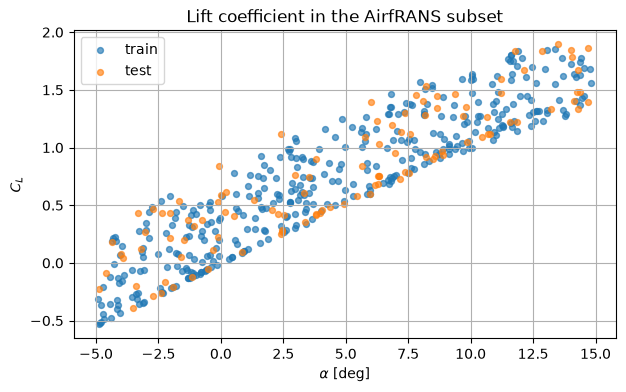

In [9]:
plt.figure(figsize=(7, 4))
for split in ["train", "test"]:
    subset = df[df["split"] == split]
    plt.scatter(subset["alpha_deg"], subset["CL"], s=18, alpha=0.65, label=split)
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$C_L$")
plt.title("Lift coefficient in the AirfRANS subset")
plt.legend()
plt.grid(True)
plt.show()

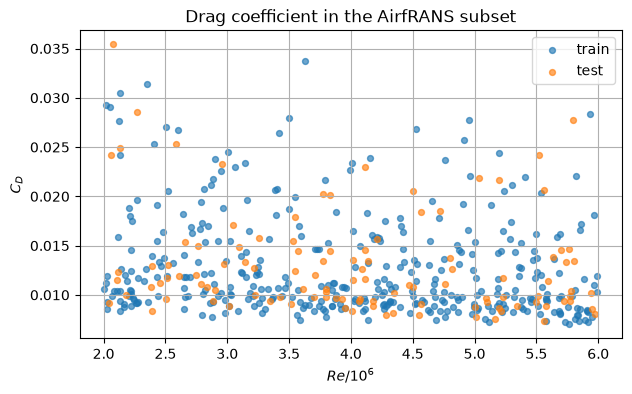

In [10]:
plt.figure(figsize=(7, 4))
for split in ["train", "test"]:
    subset = df[df["split"] == split]
    plt.scatter(subset["Re_M"], subset["CD"], s=18, alpha=0.65, label=split)
plt.xlabel(r"$Re/10^6$")
plt.ylabel(r"$C_D$")
plt.title("Drag coefficient in the AirfRANS subset")
plt.legend()
plt.grid(True)
plt.show()

## 11. Define inputs and outputs

The surrogate input vector is

$$
\mathbf{x}
=
\begin{bmatrix}
Re/10^6 & \alpha & m & p & t
\end{bmatrix}.
$$

The target is

$$
\mathbf{y}
=
\begin{bmatrix}
C_L & C_D
\end{bmatrix}.
$$

Notice that the two outputs have very different characteristic magnitudes. Therefore both inputs and outputs will be standardized before training.

In [11]:
FEATURES = ["Re_M", "alpha_deg", "m", "p", "t"]
TARGETS = ["CL", "CD"]

train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

X_train = train_df[FEATURES].to_numpy()
y_train = train_df[TARGETS].to_numpy()
X_test = test_df[FEATURES].to_numpy()
y_test = test_df[TARGETS].to_numpy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

X_train: (378, 5)
y_train: (378, 2)
X_test:  (111, 5)
y_test:  (111, 2)


## 12. Standardize the variables

The scalers are fitted **only on the training set**. Information from the test set must not influence the training process.

In [12]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
y_train_scaled = y_scaler.fit_transform(y_train)
X_test_scaled = x_scaler.transform(X_test)
y_test_scaled = y_scaler.transform(y_test)

## 13. Build the MLP surrogate

We use a deliberately small multilayer perceptron:

$$
5\rightarrow64\rightarrow64\rightarrow32\rightarrow2.
$$

The purpose is not to build the most sophisticated possible surrogate. It is to demonstrate how CFD data can be transformed into a differentiable and extremely fast aerodynamic model.

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(len(FEATURES),)),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dense(64, activation="tanh"),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(len(TARGETS)),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,690 (26.13 KB)

 Trainable params: 6,690 (26.13 KB)

 Non-trainable params: 0 (0.00 B)

## 14. Train the surrogate

We reserve part of the training data for validation. Early stopping restores the weights with the lowest validation loss.

## Animation step 1 — record snapshots while the surrogate trains

The pattern: **train once and save snapshots**. Every `SNAPSHOT_EVERY` epochs a Keras callback stores the loss histories so far, the surrogate's predictions on the test cases (for the parity plots) and its predicted lift polar for the NACA 2412-like section at $Re=4\times10^6$.

The test predictions are recorded **only for the animation**; they play no part in training, early stopping or model choice, which use the validation split alone.

In [14]:
# ================================================================
# ANIMATION STEP 1 — KERAS SNAPSHOT CALLBACK
# ================================================================
import pickle
ANIM_DIR = Path("../animations"); ANIM_DIR.mkdir(exist_ok=True)
SNAPSHOT_EVERY = 5
anim_alpha = np.linspace(-5.0, 15.0, 81)
anim_polar_inputs = x_scaler.transform(np.column_stack([
    np.full_like(anim_alpha, 4.0), anim_alpha, np.full_like(anim_alpha, 2.0),
    np.full_like(anim_alpha, 4.0), np.full_like(anim_alpha, 12.0)]))


class SurrogateSnapshotCallback(tf.keras.callbacks.Callback):
    def __init__(self, every):
        super().__init__(); self.every = every; self.snapshots = []; self.loss = []; self.val_loss = []

    def _take(self, epoch):
        pred = y_scaler.inverse_transform(self.model(X_test_scaled, training=False).numpy())
        polar = y_scaler.inverse_transform(self.model(anim_polar_inputs, training=False).numpy())
        self.snapshots.append({"epoch": epoch, "loss": list(self.loss), "val_loss": list(self.val_loss),
                               "cl_pred": pred[:, 0], "cd_pred": pred[:, 1],
                               "polar_cl": polar[:, 0], "polar_cd": polar[:, 1]})

    def on_train_begin(self, logs=None):
        self._take(0)

    def on_epoch_end(self, epoch, logs=None):
        self.loss.append(logs["loss"]); self.val_loss.append(logs["val_loss"])
        if (epoch + 1) % self.every == 0:
            self._take(epoch + 1)

    def on_train_end(self, logs=None):
        self._take(len(self.loss))      # weights here are the restored best weights


snapshot_callback = SurrogateSnapshotCallback(SNAPSHOT_EVERY)

In [15]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=40,
    restore_best_weights=True,
)

history = model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_split=0.15,
    epochs=800,
    batch_size=32,
    callbacks=[early_stopping, snapshot_callback],  # snapshot callback added for the animation
    verbose=0,
    shuffle=True,
)

print("Training stopped after", len(history.history["loss"]), "epochs")

Training stopped after 364 epochs


In [16]:
# ================================================================
# ANIMATION STEP 1b — SAVE THE SNAPSHOTS
# ================================================================
pickle.dump({"snapshots": snapshot_callback.snapshots, "y_test": y_test, "alpha": anim_alpha,
             "best_epoch": int(np.argmin(history.history["val_loss"]) + 1)},
            open(ANIM_DIR / "03_surrogate_training_snapshots.pkl", "wb"))
print(len(snapshot_callback.snapshots), "snapshots saved; best validation epoch =",
      int(np.argmin(history.history["val_loss"]) + 1))

74 snapshots saved; best validation epoch = 324


## 15. Learning curves

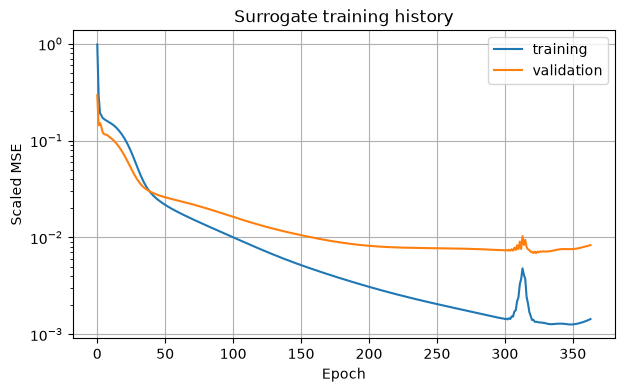

In [17]:
plt.figure(figsize=(7, 4))
plt.semilogy(history.history["loss"], label="training")
plt.semilogy(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Scaled MSE")
plt.title("Surrogate training history")
plt.legend()
plt.grid(True)
plt.show()

## 16. Predictions on unseen CFD cases

The network output is transformed back to physical aerodynamic coefficients.

In [18]:
y_pred_scaled = model.predict(X_test_scaled, verbose=0)
y_pred = y_scaler.inverse_transform(y_pred_scaled)

cl_true = y_test[:, 0]
cd_true = y_test[:, 1]
cl_pred = y_pred[:, 0]
cd_pred = y_pred[:, 1]

## 17. Quantitative accuracy

For each coefficient we calculate

$$
\mathrm{MAE},\qquad
\mathrm{RMSE},\qquad
R^2.
$$

Remember that an interpolation score is not evidence that the model will remain accurate outside the training domain.

In [19]:
def print_metrics(name, y_true, y_hat):
    mae = mean_absolute_error(y_true, y_hat)
    rmse = np.sqrt(mean_squared_error(y_true, y_hat))
    r2 = r2_score(y_true, y_hat)

    print(name)
    print(f"  MAE  = {mae:.6f}")
    print(f"  RMSE = {rmse:.6f}")
    print(f"  R2   = {r2:.6f}")
    print()

print_metrics("Lift coefficient CL", cl_true, cl_pred)
print_metrics("Drag coefficient CD", cd_true, cd_pred)

Lift coefficient CL
  MAE  = 0.016956
  RMSE = 0.020926
  R2   = 0.998644

Drag coefficient CD
  MAE  = 0.000388
  RMSE = 0.001000
  R2   = 0.963166



## 18. Parity plot for lift

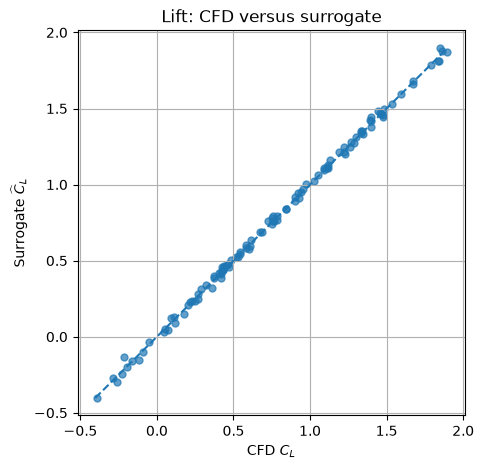

In [20]:
lower = min(cl_true.min(), cl_pred.min())
upper = max(cl_true.max(), cl_pred.max())

plt.figure(figsize=(5, 5))
plt.scatter(cl_true, cl_pred, s=25, alpha=0.7)
plt.plot([lower, upper], [lower, upper], "--")
plt.xlabel(r"CFD $C_L$")
plt.ylabel(r"Surrogate $\widehat{C}_L$")
plt.title("Lift: CFD versus surrogate")
plt.grid(True)
plt.show()

## 19. Parity plot for drag

Predicting drag is typically more demanding because $C_D$ is smaller and more sensitive to details of the pressure and viscous contributions.

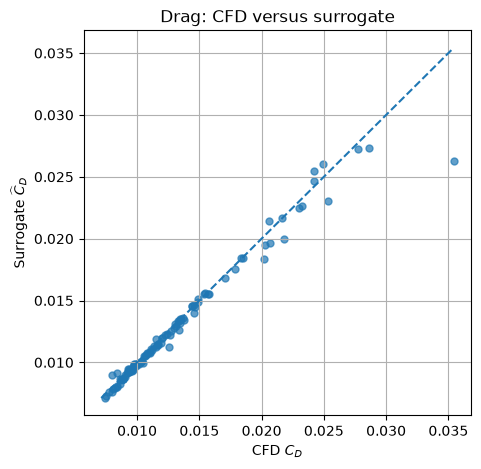

In [21]:
lower = min(cd_true.min(), cd_pred.min())
upper = max(cd_true.max(), cd_pred.max())

plt.figure(figsize=(5, 5))
plt.scatter(cd_true, cd_pred, s=25, alpha=0.7)
plt.plot([lower, upper], [lower, upper], "--")
plt.xlabel(r"CFD $C_D$")
plt.ylabel(r"Surrogate $\widehat{C}_D$")
plt.title("Drag: CFD versus surrogate")
plt.grid(True)
plt.show()

## 20. Where does the surrogate make errors?

A single global metric is not enough. We should inspect whether errors increase systematically with angle of attack, Reynolds number, or geometry.

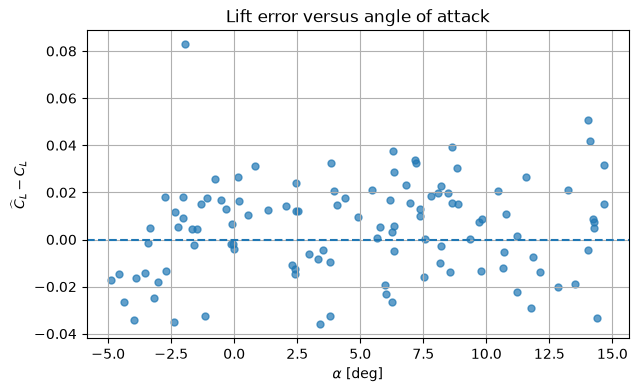

In [22]:
cl_error = cl_pred - cl_true
plt.figure(figsize=(7, 4))
plt.scatter(test_df["alpha_deg"], cl_error, s=25, alpha=0.7)
plt.axhline(0.0, linestyle="--")
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$\widehat{C}_L-C_L$")
plt.title("Lift error versus angle of attack")
plt.grid(True)
plt.show()

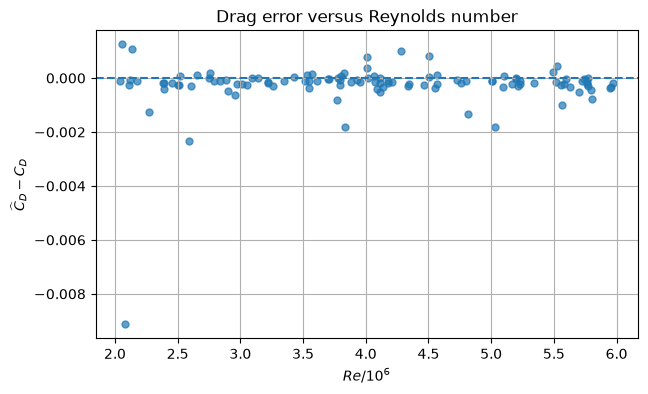

In [23]:
cd_error = cd_pred - cd_true
plt.figure(figsize=(7, 4))
plt.scatter(test_df["Re_M"], cd_error, s=25, alpha=0.7)
plt.axhline(0.0, linestyle="--")
plt.xlabel(r"$Re/10^6$")
plt.ylabel(r"$\widehat{C}_D-C_D$")
plt.title("Drag error versus Reynolds number")
plt.grid(True)
plt.show()

## 21. Compare with thin-airfoil theory

For small angles of attack, a symmetric thin airfoil suggests

$$
C_L \approx 2\pi\alpha.
$$

This is **not** an appropriate quantitative model for all AirfRANS geometries because many profiles are cambered, viscous effects are present, the Reynolds number changes, and nonlinear behavior appears at larger angles.

Nevertheless, it provides a useful physical reference.

In [24]:
cl_thin = 2.0 * np.pi * np.deg2rad(test_df["alpha_deg"].to_numpy())

rmse_thin = np.sqrt(mean_squared_error(cl_true, cl_thin))
rmse_mlp = np.sqrt(mean_squared_error(cl_true, cl_pred))

print(f"Thin-airfoil CL RMSE: {rmse_thin:.5f}")
print(f"MLP surrogate CL RMSE: {rmse_mlp:.5f}")

Thin-airfoil CL RMSE: 0.35954
MLP surrogate CL RMSE: 0.02093


## 22. Use the surrogate as an aerodynamic model

We now create the function that will be useful in the next stage. For a NACA four-digit-family geometry,

$$
(Re,\alpha,m,p,t),
$$

it immediately returns

$$
(\widehat C_L,\widehat C_D).
$$

In [25]:
def predict_aero(reynolds, alpha_deg, m, p, t):
    x = np.array([[
        reynolds / 1.0e6,
        alpha_deg,
        m,
        p,
        t,
    ]])

    x_scaled = x_scaler.transform(x)
    y_scaled = model.predict(x_scaled, verbose=0)
    cl, cd = y_scaler.inverse_transform(y_scaled)[0]
    return float(cl), float(cd)

cl_hat, cd_hat = predict_aero(
    reynolds=4.0e6,
    alpha_deg=5.0,
    m=2.0,
    p=4.0,
    t=12.0,
)

print("Example: NACA 2412-like geometry")
print(f"CL = {cl_hat:.4f}")
print(f"CD = {cd_hat:.5f}")

Example: NACA 2412-like geometry
CL = 0.7705
CD = 0.00973


## 23. Generate a surrogate polar

The next figure is **not new CFD**. It is the response predicted by the trained surrogate for a NACA 2412-like geometry at

$$
Re=4\times10^6.
$$

A surrogate prediction is trustworthy only to the extent that it has been validated against high-fidelity data in the relevant region of parameter space.

In [26]:
alpha_sweep = np.linspace(-5.0, 15.0, 100)
cl_sweep = []
cd_sweep = []

for alpha in alpha_sweep:
    cl_value, cd_value = predict_aero(
        reynolds=4.0e6,
        alpha_deg=alpha,
        m=2.0,
        p=4.0,
        t=12.0,
    )
    cl_sweep.append(cl_value)
    cd_sweep.append(cd_value)

cl_sweep = np.asarray(cl_sweep)
cd_sweep = np.asarray(cd_sweep)

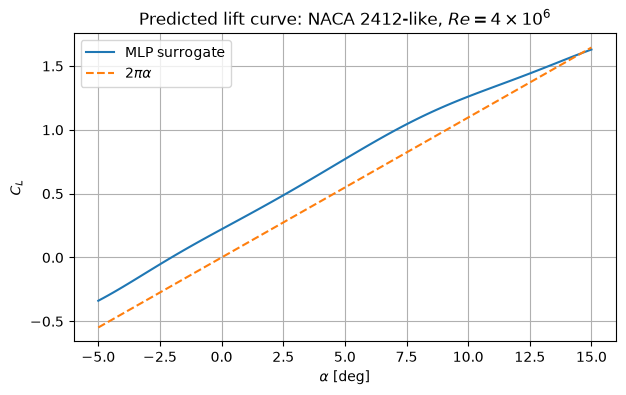

In [27]:
plt.figure(figsize=(7, 4))
plt.plot(alpha_sweep, cl_sweep, label="MLP surrogate")
plt.plot(alpha_sweep, 2.0*np.pi*np.deg2rad(alpha_sweep), "--", label=r"$2\pi\alpha$")
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$C_L$")
plt.title(r"Predicted lift curve: NACA 2412-like, $Re=4\times10^6$")
plt.legend()
plt.grid(True)
plt.show()

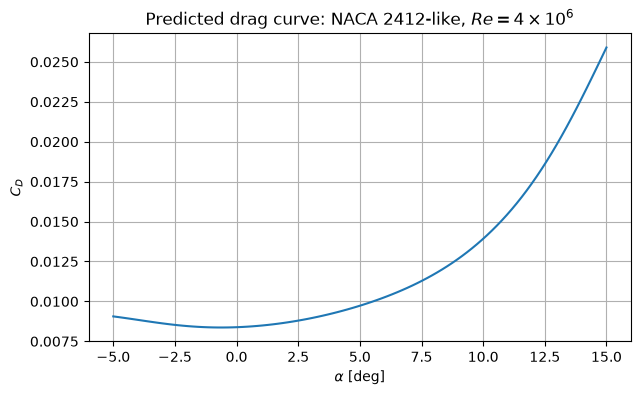

In [28]:
plt.figure(figsize=(7, 4))
plt.plot(alpha_sweep, cd_sweep)
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$C_D$")
plt.title(r"Predicted drag curve: NACA 2412-like, $Re=4\times10^6$")
plt.grid(True)
plt.show()

## 23b. Animation — watching the surrogate learn the CFD data

- **Top-left — lift parity**: surrogate $\widehat C_L$ against CFD $C_L$ on the 111 test cases.
- **Top-right — learning curves**: training and validation loss (scaled MSE) up to the current epoch.
- **Bottom-left — drag parity**: the same for $C_D$.
- **Bottom-right — predicted lift polar** of the NACA 2412-like section at $Re=4\times10^6$, against thin-airfoil theory $2\pi\alpha$.

The last frame uses the weights restored by early stopping (best validation epoch), which is the model saved in Section 24.

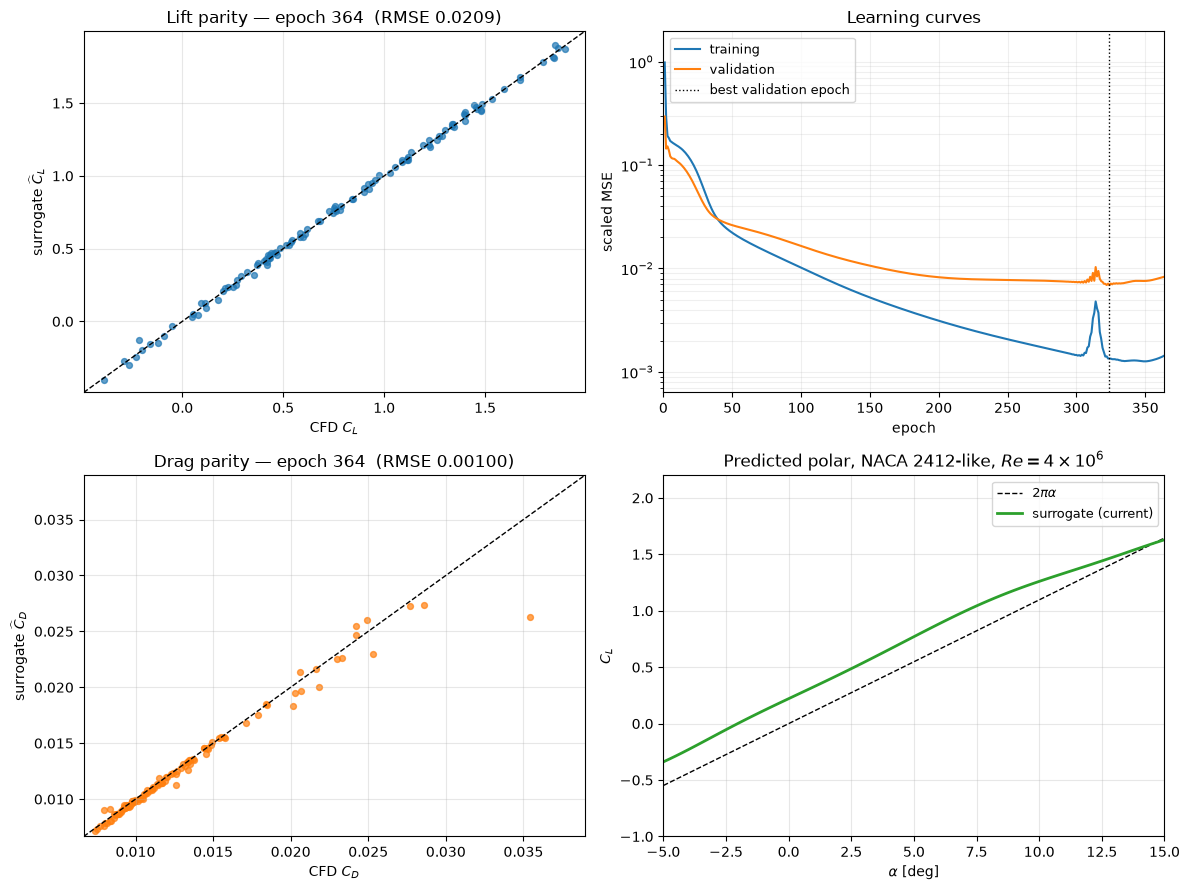

In [29]:
# ================================================================
# ANIMATION CELL 2 — PREVIEW THE FINAL FRAME
# ================================================================
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

anim_data = pickle.load(open(ANIM_DIR / "03_surrogate_training_snapshots.pkl", "rb"))
snaps = anim_data["snapshots"]
cl_t, cd_t = anim_data["y_test"][:, 0], anim_data["y_test"][:, 1]
n_epochs = len(snaps[-1]["loss"])
all_losses = np.array(snaps[-1]["loss"] + snaps[-1]["val_loss"])


def build_surrogate_dashboard():
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    ax_cl, ax_l, ax_cd, ax_p = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]
    lo, hi = cl_t.min() - 0.1, cl_t.max() + 0.1
    ax_cl.plot([lo, hi], [lo, hi], "k--", lw=1); ax_cl.set_xlim(lo, hi); ax_cl.set_ylim(lo, hi)
    sc_cl = ax_cl.scatter(cl_t, snaps[0]["cl_pred"], s=18, alpha=0.7)
    ax_cl.set_xlabel(r"CFD $C_L$"); ax_cl.set_ylabel(r"surrogate $\widehat C_L$"); ax_cl.grid(True, alpha=0.3)
    t_cl = ax_cl.set_title("")
    lo2, hi2 = cd_t.min() * 0.9, cd_t.max() * 1.1
    ax_cd.plot([lo2, hi2], [lo2, hi2], "k--", lw=1); ax_cd.set_xlim(lo2, hi2); ax_cd.set_ylim(lo2, hi2)
    sc_cd = ax_cd.scatter(cd_t, snaps[0]["cd_pred"], s=18, alpha=0.7, color="tab:orange")
    ax_cd.set_xlabel(r"CFD $C_D$"); ax_cd.set_ylabel(r"surrogate $\widehat C_D$"); ax_cd.grid(True, alpha=0.3)
    t_cd = ax_cd.set_title("")
    ax_l.set_xlim(0, n_epochs); ax_l.set_ylim(all_losses.min() * 0.5, all_losses.max() * 2); ax_l.set_yscale("log")
    tr_line, = ax_l.plot([], [], label="training"); va_line, = ax_l.plot([], [], label="validation")
    ax_l.axvline(anim_data["best_epoch"], color="k", ls=":", lw=1, label="best validation epoch")
    ax_l.set_xlabel("epoch"); ax_l.set_ylabel("scaled MSE"); ax_l.set_title("Learning curves")
    ax_l.grid(True, which="both", alpha=0.2); ax_l.legend(fontsize=9)
    a = anim_data["alpha"]
    ax_p.plot(a, 2 * np.pi * np.deg2rad(a), "k--", lw=1, label=r"$2\pi\alpha$")
    p_line, = ax_p.plot([], [], lw=2, color="tab:green", label="surrogate (current)")
    ax_p.set_xlim(a[0], a[-1]); ax_p.set_ylim(-1.0, 2.2)
    ax_p.set_xlabel(r"$\alpha$ [deg]"); ax_p.set_ylabel(r"$C_L$"); ax_p.grid(True, alpha=0.3); ax_p.legend(fontsize=9)
    ax_p.set_title(r"Predicted polar, NACA 2412-like, $Re=4\times10^6$")

    def update(k):
        s = snaps[k]
        sc_cl.set_offsets(np.column_stack([cl_t, s["cl_pred"]]))
        sc_cd.set_offsets(np.column_stack([cd_t, s["cd_pred"]]))
        r_cl = np.sqrt(np.mean((s["cl_pred"] - cl_t)**2)); r_cd = np.sqrt(np.mean((s["cd_pred"] - cd_t)**2))
        t_cl.set_text(f"Lift parity — epoch {s['epoch']}  (RMSE {r_cl:.4f})")
        t_cd.set_text(f"Drag parity — epoch {s['epoch']}  (RMSE {r_cd:.5f})")
        ep = np.arange(1, len(s["loss"]) + 1)
        tr_line.set_data(ep, s["loss"]); va_line.set_data(ep, s["val_loss"])
        p_line.set_data(a, s["polar_cl"])
        return [sc_cl, sc_cd, tr_line, va_line, p_line]

    fig.tight_layout()
    return fig, update


fig, update = build_surrogate_dashboard()
update(len(snaps) - 1)
fig.savefig(ANIM_DIR / "03_surrogate_training_dashboard_final_frame.png", dpi=120)
plt.show()

In [30]:
# ================================================================
# ANIMATION CELL 3 — RENDER THE ANIMATION
# ================================================================
N_HOLD = 12
frames = list(range(len(snaps))) + [len(snaps) - 1] * N_HOLD
print("Total frames:", len(frames))
fig, update = build_surrogate_dashboard()
anim = FuncAnimation(fig, lambda i: update(frames[i]), frames=len(frames), interval=120, blit=False)
anim.save(ANIM_DIR / "03_surrogate_training_dashboard.mp4", writer="ffmpeg", fps=8, dpi=100)
plt.close(fig)
print("Saved:", ANIM_DIR / "03_surrogate_training_dashboard.mp4")
HTML(anim.to_html5_video())

Total frames: 86


Saved: animations/surrogate_training_dashboard.mp4


### Animation analysis questions

✏️ **A1** — Which coefficient is learned first, lift or drag? Compare the epoch at which each test RMSE first comes within 20 % of its final value.

✏️ **A2** — How far past the best validation epoch does training continue, and what does early stopping restore?

✏️ **A3** — Where along the polar does the surrogate differ most from $2\pi\alpha$, and why is that expected for a cambered section?

The next cell computes the numbers each answer needs.

In [31]:
# ================================================================
# ANIMATION ANALYSIS — NUMBERS FOR A1–A3
# ================================================================
ep = np.array([s["epoch"] for s in snaps])
r_cl = np.array([np.sqrt(np.mean((s["cl_pred"] - cl_t)**2)) for s in snaps])
r_cd = np.array([np.sqrt(np.mean((s["cd_pred"] - cd_t)**2)) for s in snaps])
print(f"A1: CL within 20% of final RMSE at epoch {ep[np.argmax(r_cl <= 1.2 * r_cl[-1])]}, "
      f"CD at epoch {ep[np.argmax(r_cd <= 1.2 * r_cd[-1])]}  (final RMSE CL {r_cl[-1]:.4f}, CD {r_cd[-1]:.5f})")
print(f"A2: epochs run {n_epochs}, best validation epoch {anim_data['best_epoch']}, "
      f"extra epochs {n_epochs - anim_data['best_epoch']} (= patience)")
diff = snaps[-1]["polar_cl"] - 2 * np.pi * np.deg2rad(anim_data["alpha"])
print(f"A3: surrogate - thin airfoil at alpha=0: {np.interp(0, anim_data['alpha'], diff):+.3f}; "
      f"at alpha=5: {np.interp(5, anim_data['alpha'], diff):+.3f}; at alpha=15: {np.interp(15, anim_data['alpha'], diff):+.3f}")

A1: CL within 20% of final RMSE at epoch 205, CD at epoch 75  (final RMSE CL 0.0209, CD 0.00100)
A2: epochs run 364, best validation epoch 324, extra epochs 40 (= patience)
A3: surrogate - thin airfoil at alpha=0: +0.221; at alpha=5: +0.222; at alpha=15: -0.016


## 24. Save the surrogate

We save the neural network and the input/output scalers so that they can later be called from a Gymnasium environment.

In [32]:
MODEL_DIR = Path("../models/03_airfrans_cfd_surrogate"); MODEL_DIR.mkdir(exist_ok=True)  # added: models live in trained_models/
MODEL_FILE = MODEL_DIR / "airfrans_cl_cd_surrogate.keras"
SCALER_FILE = MODEL_DIR / "airfrans_cl_cd_scalers.joblib"

model.save(MODEL_FILE)
joblib.dump(
    {
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
        "features": FEATURES,
        "targets": TARGETS,
    },
    SCALER_FILE,
)

print("Saved model:  ", MODEL_FILE)
print("Saved scalers:", SCALER_FILE)

Saved model:   trained_models/airfrans_cl_cd_surrogate.keras
Saved scalers: trained_models/airfrans_cl_cd_scalers.joblib


## 25. Reload the model independently

A surrogate becomes useful when it can be separated from the notebook in which it was trained.

In [33]:
loaded_model = tf.keras.models.load_model(MODEL_FILE)
loaded_data = joblib.load(SCALER_FILE)
loaded_x_scaler = loaded_data["x_scaler"]
loaded_y_scaler = loaded_data["y_scaler"]


def loaded_surrogate(reynolds, alpha_deg, m, p, t):
    x = np.array([[
        reynolds / 1.0e6,
        alpha_deg,
        m,
        p,
        t,
    ]])

    x_scaled = loaded_x_scaler.transform(x)
    prediction_scaled = loaded_model.predict(x_scaled, verbose=0)
    cl, cd = loaded_y_scaler.inverse_transform(prediction_scaled)[0]
    return float(cl), float(cd)

print(loaded_surrogate(4.0e6, 5.0, 2.0, 4.0, 12.0))

(0.7704553604125977, 0.009729189798235893)


## 26. What did we actually learn?

The original low-order model used

$$
C_L = 2\pi\alpha.
$$

The new model is

$$
\begin{bmatrix}
\widehat C_L\\
\widehat C_D
\end{bmatrix}
=
\mathcal N_\theta(Re,\alpha,m,p,t),
$$

where $\mathcal N_\theta$ has been fitted to RANS simulations.

The neural network can therefore represent dependencies on Reynolds number, airfoil camber, camber location, thickness, angle of attack, and nonlinear interactions between these quantities.

## 27. What the surrogate cannot do

This model has important limitations.

### It is static

It predicts steady RANS coefficients. It does not contain aerodynamic memory and therefore cannot reproduce unsteady lift, vortex shedding, dynamic stall, or gust history.

### It has no flap variable

AirfRANS does not contain the flap deflection $\delta_f$. Therefore this surrogate cannot yet directly replace the earlier flap model.

### It should not be trusted outside the training domain

Neural networks can produce smooth-looking answers outside the data range even when those answers are physically meaningless.

## 28. Connection to the DRL airfoil environment

In Stage 2 we used

```python
CL_qs = 2*np.pi*alpha_eff
CD = CD0 + k*CL**2
```

We can now replace these equations by

```python
CL_qs, CD = loaded_surrogate(
    Re,
    alpha_eff,
    m,
    p,
    t,
)
```

and retain the unsteady first-order response

$$
\tau_L \dot C_L = C_{L,\mathrm{qs}}-C_L.
$$

This gives a hybrid model:

$$
\boxed{
\text{CFD steady aerodynamics}
+
\text{low-order unsteady dynamics}
}
$$

which is still cheap enough for reinforcement learning.

## 29. Suggested exercises

1. Compare MLP architectures `32-32`, `64-64-32`, and `128-128-64`.
2. Remove Reynolds number and quantify the loss of accuracy.
3. Train a single-output model for only $C_L$.
4. Repeat the training in a scarce-data regime.
5. Use the official AirfRANS Reynolds-number or angle-of-attack extrapolation splits.
6. Extend the representation to the five-digit family.
7. Train an ensemble of MLPs and use prediction spread as a simple uncertainty indicator.

# 29b. Suggested exercises — executed

All exercises reuse the data split, scaling rules and training settings of Sections 11–14 (tanh MLP, Adam $10^{-3}$, MSE, 15 % validation split, early stopping with patience 40, batch 32) unless the exercise changes them. Every configuration is trained with **3 seeds** and reported as mean ± standard deviation, because a single small-network run can vary noticeably. Tables and figures are saved in `exercise_results/`; the ensemble members of Exercise 7 are saved in `trained_models/exercises/`.

In [34]:
# ================================================================
# EXERCISES — SHARED SETUP
# ================================================================
import time
EX_DIR = Path("../results/03_airfrans_cfd_surrogate"); EX_DIR.mkdir(exist_ok=True)
EX_MODEL_DIR = Path("../models/03_airfrans_cfd_surrogate") / "exercises"; EX_MODEL_DIR.mkdir(parents=True, exist_ok=True)
SEEDS = [0, 1, 2]


def fit_surrogate(train_frame, features=FEATURES, targets=TARGETS, layers=(64, 64, 32), seed=0, save_as=None):
    """Fit scalers on the training frame only, then train exactly as in Section 14."""
    tf.keras.utils.set_random_seed(seed)
    xs, ys = StandardScaler(), StandardScaler()
    Xs = xs.fit_transform(train_frame[features].to_numpy()); Ys = ys.fit_transform(train_frame[targets].to_numpy())
    net = tf.keras.Sequential([tf.keras.layers.Input(shape=(len(features),))] +
                              [tf.keras.layers.Dense(u, activation="tanh") for u in layers] +
                              [tf.keras.layers.Dense(len(targets))])
    net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    h = net.fit(Xs, Ys, validation_split=0.15, epochs=800, batch_size=32, verbose=0, shuffle=True,
                callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True)])
    if save_as is not None:
        net.save(EX_MODEL_DIR / f"{save_as}.keras")
        joblib.dump({"x_scaler": xs, "y_scaler": ys, "features": list(features), "targets": list(targets)},
                    EX_MODEL_DIR / f"{save_as}_scalers.joblib")

    def predict(frame):
        return ys.inverse_transform(net(xs.transform(frame[features].to_numpy()), training=False).numpy())

    predict.n_params = net.count_params(); predict.epochs = len(h.history["loss"])
    return predict


def score(predict, test_frame, targets=TARGETS):
    pred = predict(test_frame); out = {}
    for j, name in enumerate(targets):
        yt = test_frame[name].to_numpy()
        out[f"{name}_RMSE"] = float(np.sqrt(mean_squared_error(yt, pred[:, j])))
        out[f"{name}_MAE"] = float(mean_absolute_error(yt, pred[:, j]))
        out[f"{name}_R2"] = float(r2_score(yt, pred[:, j]))
    return out


def run_seeds(label, train_frame, test_frame, **kw):
    rows = []
    for s in SEEDS:
        p = fit_surrogate(train_frame, seed=s, **{k: v for k, v in kw.items() if k != "targets_score"})
        rows.append({**score(p, test_frame, kw.get("targets", TARGETS)), "params": p.n_params, "epochs": p.epochs})
    d = pd.DataFrame(rows)
    summary = {"configuration": label, "n_train": len(train_frame), "n_test": len(test_frame)}
    for c in d.columns:
        summary[c] = d[c].mean()
        if c.endswith(("RMSE", "R2")):
            summary[c + "_std"] = d[c].std()
    return summary


t0 = time.time()
reference = run_seeds("reference 64-64-32", train_df, test_df)
print(f"reference configuration ({time.time() - t0:.0f} s for 3 seeds)")
pd.DataFrame([reference]).round(5)

reference configuration (30 s for 3 seeds)


,configuration,n_train,n_test,CL_RMSE,CL_RMSE_std,CL_MAE,CL_R2,CL_R2_std,CD_RMSE,CD_RMSE_std,CD_MAE,CD_R2,CD_R2_std,params,epochs
0,reference 64-64-32,378,111,0.02364,0.00381,0.01902,0.99824,0.00058,0.0008,0.00015,0.00034,0.976,0.00871,6690.0,336.33333


## Exercise 1 — Architectures `32-32`, `64-64-32`, `128-128-64` *(executed)*

In [35]:
rows = []
for layers in [(32, 32), (64, 64, 32), (128, 128, 64)]:
    label = "-".join(map(str, layers))
    rows.append(reference if layers == (64, 64, 32) else run_seeds(label, train_df, test_df, layers=layers))
    rows[-1]["configuration"] = label
ex1_table = pd.DataFrame(rows)
ex1_table.to_csv(EX_DIR / "ex1_architectures.csv", index=False)
ex1_table[["configuration", "params", "epochs", "CL_RMSE", "CL_RMSE_std", "CL_R2", "CD_RMSE", "CD_RMSE_std", "CD_R2"]].round(6)

,configuration,params,epochs,CL_RMSE,CL_RMSE_std,CL_R2,CD_RMSE,CD_RMSE_std,CD_R2
0,32-32,1314.0,701.666667,0.017423,0.001687,0.999054,0.000756,0.000056,0.978879
1,64-64-32,6690.0,336.333333,0.023643,0.003812,0.998239,0.000798,0.000150,0.976003
2,128-128-64,25666.0,292.666667,0.026048,0.006386,0.997815,0.000826,0.000078,0.974731


## Exercise 2 — Remove the Reynolds number *(executed)*

The input becomes $(\alpha, m, p, t)$. Any accuracy lost is the part of the coefficients' variation that the network can only explain through $Re$; drag, being partly viscous, is expected to suffer more than lift.

In [36]:
no_re = run_seeds("without Re", train_df, test_df, features=["alpha_deg", "m", "p", "t"])
ex2_table = pd.DataFrame([{**reference, "configuration": "with Re (reference)"}, no_re])
ex2_table.to_csv(EX_DIR / "ex2_without_reynolds.csv", index=False)
ex2_table[["configuration", "CL_RMSE", "CL_RMSE_std", "CL_R2", "CD_RMSE", "CD_RMSE_std", "CD_R2"]].round(6)

,configuration,CL_RMSE,CL_RMSE_std,CL_R2,CD_RMSE,CD_RMSE_std,CD_R2
0,with Re (reference),0.023643,0.003812,0.998239,0.000798,0.000150,0.976003
1,without Re,0.030070,0.001800,0.997194,0.001174,0.000059,0.949165


## Exercise 3 — A single-output model for $C_L$ only *(executed)*

With two outputs, the shared hidden layers must serve both coefficients. A dedicated lift network removes that compromise; the comparison shows whether the shared representation helps or hinders lift.

In [37]:
cl_only = run_seeds("CL only", train_df, test_df, targets=["CL"])
ex3_table = pd.DataFrame([{**reference, "configuration": "CL and CD (reference)"}, cl_only])
ex3_table.to_csv(EX_DIR / "ex3_single_output.csv", index=False)
ex3_table[["configuration", "params", "CL_RMSE", "CL_RMSE_std", "CL_MAE", "CL_R2"]].round(6)

,configuration,params,CL_RMSE,CL_RMSE_std,CL_MAE,CL_R2
0,CL and CD (reference),6690.0,0.023643,0.003812,0.019020,0.998239
1,CL only,6657.0,0.020000,0.003105,0.014617,0.998742


## Exercise 4 — Scarce-data regime *(executed)*

Random subsets of 10 %, 25 %, 50 % and 100 % of the 378 training simulations are used (a different subset for each seed); the test set is unchanged.

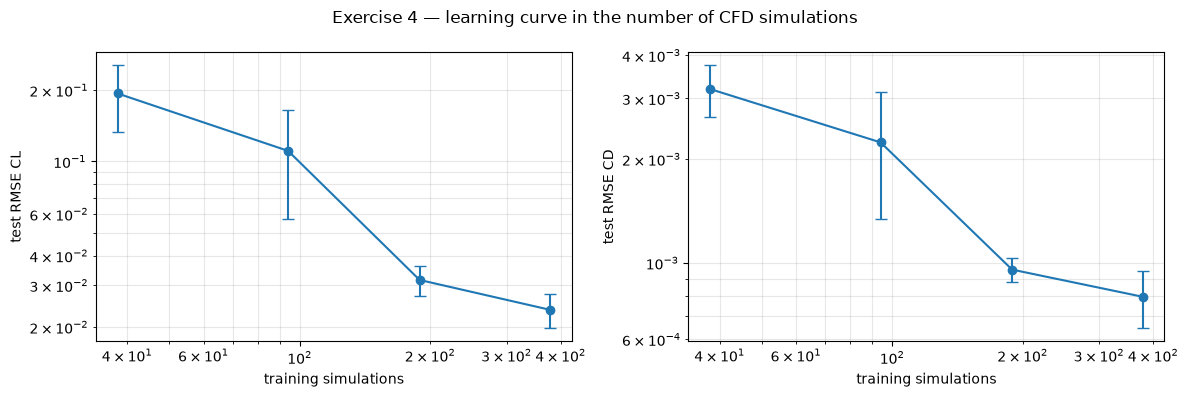

,fraction,n_train,CL_RMSE,CL_RMSE_std,CL_R2,CD_RMSE,CD_RMSE_std,CD_R2
0,0.10,38,0.193759,0.060563,0.876201,0.003193,0.000544,0.617102
1,0.25,94,0.110874,0.053932,0.955938,0.002236,0.000897,0.796000
2,0.50,189,0.031612,0.004519,0.996864,0.000956,0.000078,0.966161
3,1.00,378,0.023643,0.003812,0.998239,0.000798,0.000150,0.976003


In [38]:
rows = []
for frac in (0.10, 0.25, 0.50, 1.00):
    per_seed = []
    for s in SEEDS:
        sub = train_df.sample(frac=frac, random_state=s) if frac < 1 else train_df
        p = fit_surrogate(sub, seed=s)
        per_seed.append(score(p, test_df))
    d = pd.DataFrame(per_seed)
    rows.append({"fraction": frac, "n_train": int(round(frac * len(train_df))),
                 **{c: d[c].mean() for c in d.columns}, "CL_RMSE_std": d.CL_RMSE.std(), "CD_RMSE_std": d.CD_RMSE.std()})
ex4_table = pd.DataFrame(rows)
ex4_table.to_csv(EX_DIR / "ex4_scarce_data.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, name in zip(ax, ["CL", "CD"]):
    a.errorbar(ex4_table.n_train, ex4_table[f"{name}_RMSE"], yerr=ex4_table[f"{name}_RMSE_std"], marker="o", capsize=4)
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("training simulations"); a.set_ylabel(f"test RMSE {name}")
    a.grid(True, which="both", alpha=0.3)
fig.suptitle("Exercise 4 — learning curve in the number of CFD simulations"); fig.tight_layout()
fig.savefig(EX_DIR / "ex4_scarce_data.png", dpi=120); plt.show()
ex4_table[["fraction", "n_train", "CL_RMSE", "CL_RMSE_std", "CL_R2", "CD_RMSE", "CD_RMSE_std", "CD_R2"]].round(6)

## Exercise 5 — Extrapolation in Reynolds number and angle of attack *(executed, emulated)*

AirfRANS ships official extrapolation tasks, but their case lists live in the full dataset's `manifest.json`, which is not available here. We therefore **emulate** the idea with the 489 cases in the CSV:

- **Reynolds task:** train on official-training cases with $3\le Re/10^6\le5$; test on (i) official-test cases inside that band (*interpolation*) and (ii) all cases outside it (*extrapolation*).
- **Angle task:** the same with $-2.5^\circ\le\alpha\le12.5^\circ$.

The comparison isolates the effect of leaving the training range, with the same model and settings.

In [39]:
rows = []
for label, col, lo, hi in [("Reynolds", "Re_M", 3.0, 5.0), ("angle of attack", "alpha_deg", -2.5, 12.5)]:
    inside = df[col].between(lo, hi)
    tr = df[(df.split == "train") & inside]
    te_in = df[(df.split == "test") & inside]
    te_out = df[~inside]
    per_in, per_out = [], []
    for s in SEEDS:
        p = fit_surrogate(tr, seed=s)
        per_in.append(score(p, te_in)); per_out.append(score(p, te_out))
    for kind, per, te in (("interpolation (inside band)", per_in, te_in), ("extrapolation (outside band)", per_out, te_out)):
        d = pd.DataFrame(per)
        rows.append({"task": label, "band": f"{lo} to {hi}", "test": kind, "n_train": len(tr), "n_test": len(te),
                     **{c: d[c].mean() for c in d.columns}, "CL_RMSE_std": d.CL_RMSE.std(), "CD_RMSE_std": d.CD_RMSE.std()})
ex5_table = pd.DataFrame(rows)
ex5_table.to_csv(EX_DIR / "ex5_extrapolation.csv", index=False)
ex5_table[["task", "band", "test", "n_train", "n_test", "CL_RMSE", "CL_RMSE_std", "CD_RMSE", "CD_RMSE_std", "CL_R2", "CD_R2"]].round(6)

,task,band,test,n_train,n_test,CL_RMSE,CL_RMSE_std,CD_RMSE,CD_RMSE_std,CL_R2,CD_R2
0,Reynolds,3.0 to 5.0,interpolation (inside band),186,53,0.033172,0.012437,0.000600,0.000099,0.995316,0.972919
1,Reynolds,3.0 to 5.0,extrapolation (outside band),186,250,0.060882,0.015705,0.001472,0.000327,0.989693,0.926755
2,angle of attack,-2.5 to 12.5,interpolation (inside band),300,87,0.016479,0.003023,0.000432,0.000027,0.998757,0.981564
3,angle of attack,-2.5 to 12.5,extrapolation (outside band),300,102,0.037475,0.006268,0.002407,0.000148,0.997981,0.905011


## Exercise 6 — Extend to the five-digit family *(requires the full AirfRANS dataset)*

Five-digit cases carry **four** geometry parameters in their names (versus three for four-digit), so the input becomes $(Re,\alpha,g_1,g_2,g_3,g_4)$ for that family, or a common encoding is needed if both families are mixed. The coefficient CSV supplied with the data contains only four-digit cases, so this exercise can only run where the full dataset (≈9.3 GB, Part A) is available. The cell below runs the extraction and training automatically if it finds the dataset, and otherwise reports what is missing.

In [40]:
if manifest_file.exists():
    five = [n for n in manifest["full_train"] + manifest["full_test"] if len(geometry_parameters_from_name(n)) == 4]
    recs = []
    for name in five:
        sim = af.Simulation(root=str(DATA_ROOT), name=name)
        g = geometry_parameters_from_name(name); fc = sim.force_coefficient(reference=True)
        recs.append({"split": "train" if name in manifest["full_train"] else "test",
                     "Re_M": sim.inlet_velocity / NU_DATASET / 1e6, "alpha_deg": np.rad2deg(sim.angle_of_attack),
                     "g1": g[0], "g2": g[1], "g3": g[2], "g4": g[3], "CL": float(fc[1][0]), "CD": float(fc[0][0])})
    df5 = pd.DataFrame(recs); df5.to_csv(EX_DIR / "ex6_five_digit_coefficients.csv", index=False)
    res5 = run_seeds("five-digit", df5[df5.split == "train"], df5[df5.split == "test"],
                     features=["Re_M", "alpha_deg", "g1", "g2", "g3", "g4"])
    pd.DataFrame([res5]).to_csv(EX_DIR / "ex6_five_digit.csv", index=False); print(res5)
else:
    msg = ("Exercise 6 not run: the full AirfRANS dataset was not found at "
           f"{DATA_ROOT}. Download it (Part A, DOWNLOAD_DATASET=True) and re-run this cell.")
    (EX_DIR / "ex6_five_digit_NOT_RUN.txt").write_text(msg + "\n"); print(msg)

Exercise 6 not run: the full AirfRANS dataset was not found at /path/to/AirfRANS/Dataset. Download it (Part A, DOWNLOAD_DATASET=True) and re-run this cell.


## Exercise 7 — Ensemble of MLPs and prediction spread as an uncertainty indicator *(executed)*

Five reference networks (seeds 0–4) are trained on the same data. The ensemble mean is the prediction and the standard deviation across members is the **spread**. Two checks: (a) on the test set, do cases with larger spread also have larger errors? (b) along a polar extended beyond the training angles ($-10^\circ$ to $20^\circ$, data cover about $-5^\circ$ to $15^\circ$), does the spread grow outside the data? The members are saved in `trained_models/exercises/`.

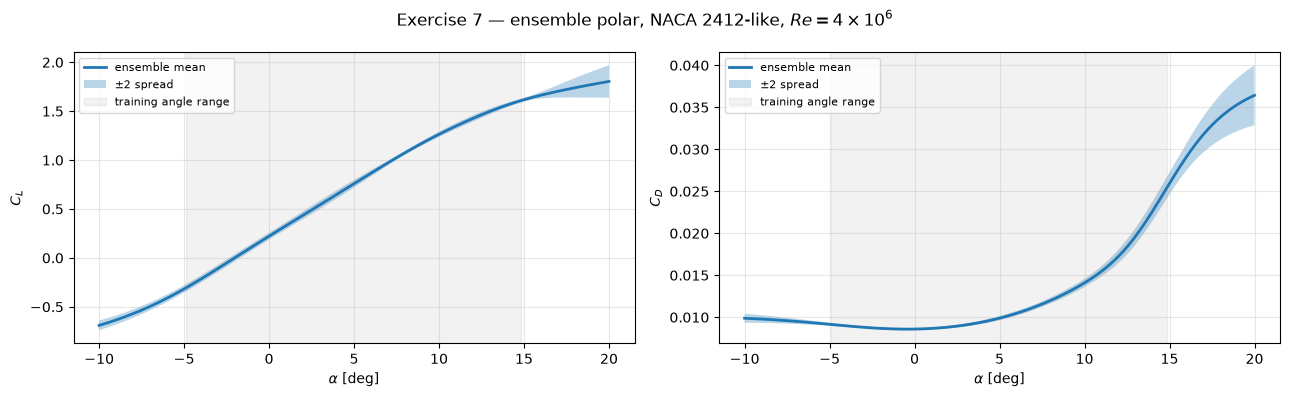

CL spread: mean inside data range 0.0163, outside 0.0318
CD spread: mean inside data range 0.000190, outside 0.000690


,coefficient,ensemble_RMSE,mean_member_RMSE,mean_spread,spearman_spread_vs_error,p_value
0,CL,0.012889,0.024501,0.019435,0.113373,0.236111
1,CD,0.000725,0.000769,0.000205,0.527747,0.000000


In [41]:
from scipy.stats import spearmanr
members = [fit_surrogate(train_df, seed=s, save_as=f"ensemble_member_{s}") for s in range(5)]
P = np.stack([m(test_df) for m in members])           # (members, cases, 2)
mean, spread = P.mean(axis=0), P.std(axis=0)
rows = []
for j, name in enumerate(TARGETS):
    err = np.abs(mean[:, j] - test_df[name].to_numpy())
    rho, pval = spearmanr(spread[:, j], err)
    rows.append({"coefficient": name, "ensemble_RMSE": float(np.sqrt(np.mean(err**2))),
                 "mean_member_RMSE": float(np.mean([np.sqrt(np.mean((P[k, :, j] - test_df[name].to_numpy())**2)) for k in range(5)])),
                 "mean_spread": float(spread[:, j].mean()), "spearman_spread_vs_error": float(rho), "p_value": float(pval)})
ex7_table = pd.DataFrame(rows); ex7_table.to_csv(EX_DIR / "ex7_ensemble.csv", index=False)

a_ext = np.linspace(-10, 20, 121)
frame = pd.DataFrame({"Re_M": 4.0, "alpha_deg": a_ext, "m": 2.0, "p": 4.0, "t": 12.0})
Pp = np.stack([m(frame) for m in members])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, (a, name) in enumerate(zip(ax, [r"$C_L$", r"$C_D$"])):
    mu, sd = Pp[:, :, j].mean(0), Pp[:, :, j].std(0)
    a.plot(a_ext, mu, lw=2, label="ensemble mean"); a.fill_between(a_ext, mu - 2 * sd, mu + 2 * sd, alpha=0.3, label="±2 spread")
    a.axvspan(df.alpha_deg.min(), df.alpha_deg.max(), color="gray", alpha=0.1, label="training angle range")
    a.set_xlabel(r"$\alpha$ [deg]"); a.set_ylabel(name); a.grid(True, alpha=0.3); a.legend(fontsize=8)
fig.suptitle(r"Exercise 7 — ensemble polar, NACA 2412-like, $Re=4\times10^6$"); fig.tight_layout()
fig.savefig(EX_DIR / "ex7_ensemble_polar.png", dpi=120); plt.show()
inside = (a_ext >= df.alpha_deg.min()) & (a_ext <= df.alpha_deg.max())
print(f"CL spread: mean inside data range {Pp[:, inside, 0].std(0).mean():.4f}, outside {Pp[:, ~inside, 0].std(0).mean():.4f}")
print(f"CD spread: mean inside data range {Pp[:, inside, 1].std(0).mean():.6f}, outside {Pp[:, ~inside, 1].std(0).mean():.6f}")
ex7_table.round(6)

In [42]:
# ================================================================
# INDEX OF SAVED OUTPUTS
# ================================================================
for p in sorted(EX_DIR.iterdir()):
    print(p)
for p in sorted(Path("../models/03_airfrans_cfd_surrogate").rglob("*")):
    print(p)

exercise_results/ex1_architectures.csv
exercise_results/ex2_without_reynolds.csv
exercise_results/ex3_single_output.csv
exercise_results/ex4_scarce_data.csv
exercise_results/ex4_scarce_data.png
exercise_results/ex5_extrapolation.csv
exercise_results/ex6_five_digit_NOT_RUN.txt
exercise_results/ex7_ensemble.csv
exercise_results/ex7_ensemble_polar.png
trained_models/airfrans_cl_cd_scalers.joblib
trained_models/airfrans_cl_cd_surrogate.keras
trained_models/exercises
trained_models/exercises/ensemble_member_0.keras
trained_models/exercises/ensemble_member_0_scalers.joblib
trained_models/exercises/ensemble_member_1.keras
trained_models/exercises/ensemble_member_1_scalers.joblib
trained_models/exercises/ensemble_member_2.keras
trained_models/exercises/ensemble_member_2_scalers.joblib
trained_models/exercises/ensemble_member_3.keras
trained_models/exercises/ensemble_member_3_scalers.joblib
trained_models/exercises/ensemble_member_4.keras
trained_models/exercises/ensemble_member_4_scalers.jobli

## 30. Main message

A CFD surrogate is not simply a neural network fitted to arbitrary data.

Its usefulness depends on a sequence of physically meaningful decisions:

$$
\boxed{
\begin{array}{c}
\text{define the parameter space}\\
\downarrow\\
\text{generate or obtain CFD data}\\
\downarrow\\
\text{choose physically meaningful inputs and outputs}\\
\downarrow\\
\text{separate train and test regimes}\\
\downarrow\\
\text{train the surrogate}\\
\downarrow\\
\text{validate errors and domain of applicability}\\
\downarrow\\
\text{embed it in optimization or control}
\end{array}
}
$$

In the next step we can replace the analytical aerodynamics of our Gymnasium airfoil environment by this CFD-informed surrogate.

## References and resources

- Bonnet, F., Mazari, J. A., Cinnella, P. & Gallinari, P. **AirfRANS: High Fidelity Computational Fluid Dynamics Dataset for Approximating Reynolds-Averaged Navier–Stokes Solutions.** NeurIPS 2022 Datasets and Benchmarks Track.
- AirfRANS documentation: https://airfrans.readthedocs.io/
- AirfRANS library: https://github.com/Extrality/airfrans_lib

# Appendix — written answers and findings

These cells are appended at the end so that the numbering of all executed cells is unchanged.

## Animation analysis — answers


- **A1** — Drag settles first: its test RMSE is within 20 % of its final value by epoch 75, lift only by epoch 205. Lift has the larger, more structured variation (angle, camber) that the network keeps refining.
- **A2** — Training ran 364 epochs; the best validation loss was at epoch 324, so training continued for exactly the patience of 40 epochs, after which early stopping restored the epoch-324 weights (the model that is saved).
- **A3** — The surrogate sits about +0.22 above $2\pi\alpha$ at 0° and 5° — the 2412 section is cambered, so it lifts at zero angle — and the gap closes to about zero at 15°, where the surrogate's lift curve has flattened below the thin-airfoil slope.

## Summary of the executed exercises

| # | Finding (3 seeds each, mean test RMSE) |
|---|---|
| 1 | Smallest network wins on this 378-case set: 32-32 gives $C_L$ 0.0174 / $C_D$ 0.00076, vs 0.0236 / 0.00080 (64-64-32) and 0.0260 / 0.00083 (128-128-64). |
| 2 | Removing $Re$ costs little for lift (0.0301) and more for drag (0.00117, $R^2$ 0.949 vs 0.976). |
| 3 | A dedicated $C_L$ network is slightly better (0.0200 vs 0.0236). |
| 4 | Error falls steeply with data: $C_L$ 0.194 (38 cases) → 0.111 (94) → 0.032 (189) → 0.024 (378). |
| 5 | Leaving the training band (emulated splits) multiplies the error: $Re$ task $C_L$ 0.033 → 0.061; angle task $C_D$ 0.00043 → 0.00241. |
| 6 | Not run: needs the full AirfRANS dataset (five-digit cases). |
| 7 | The 5-member ensemble halves the lift error (0.0129 vs 0.0245 per member); spread correlates with drag error (Spearman 0.53) but hardly with lift error (0.11), and doubles outside the training angles. |

## Appendix B — The provided surrogate files

`airfrans_cl_cd_surrogate.keras` and `airfrans_cl_cd_scalers.joblib` were provided together with the coefficient CSV (copied unchanged into `provided_surrogate/`). They are the network and scalers this notebook saves in Section 24, from the original run. **Stage 4 uses these provided files**, so the cell below measures their accuracy on the same 111 test simulations, with the same metrics as Section 17, and compares them with the surrogate retrained in this execution (`trained_models/`). The cell is self-contained: it reloads everything from disk.

In [43]:
# ================================================================
# EVALUATE THE PROVIDED SURROGATE FILES — self-contained
# ================================================================
from pathlib import Path
import numpy as np, pandas as pd, joblib, tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = pd.read_csv("../data/airfrans_4digit_coefficients.csv")
test = data[data["split"] == "test"]
rows = []
for label, folder in [("provided (used by Stage 4)", Path("../data")),
                      ("retrained in this execution", Path("../models/03_airfrans_cfd_surrogate"))]:
    net = tf.keras.models.load_model(folder / "airfrans_cl_cd_surrogate.keras")
    sc = joblib.load(folder / "airfrans_cl_cd_scalers.joblib")
    pred = sc["y_scaler"].inverse_transform(net.predict(sc["x_scaler"].transform(test[sc["features"]].to_numpy()), verbose=0))
    demo = sc["y_scaler"].inverse_transform(net.predict(sc["x_scaler"].transform([[4.0, 5.0, 2.0, 4.0, 12.0]]), verbose=0))[0]
    row = {"surrogate": label, "params": net.count_params()}
    for j, name in enumerate(sc["targets"]):
        y = test[name].to_numpy()
        row[f"{name}_MAE"] = mean_absolute_error(y, pred[:, j])
        row[f"{name}_RMSE"] = float(np.sqrt(mean_squared_error(y, pred[:, j])))
        row[f"{name}_R2"] = r2_score(y, pred[:, j])
    row["demo_CL (Re 4e6, a 5, 2412)"], row["demo_CD"] = float(demo[0]), float(demo[1])
    rows.append(row)
provided_eval = pd.DataFrame(rows)
provided_eval.to_csv("../results/03_airfrans_cfd_surrogate/provided_surrogate_evaluation.csv", index=False)
provided_eval.round(6)

,surrogate,params,CL_MAE,CL_RMSE,CL_R2,CD_MAE,CD_RMSE,CD_R2,"demo_CL (Re 4e6, a 5, 2412)",demo_CD
0,provided (used by Stage 4),6690,0.019268,0.025934,0.997918,0.000366,0.000866,0.972377,0.759491,0.009674
1,retrained in this execution,6690,0.016956,0.020926,0.998644,0.000388,0.001000,0.963166,0.770455,0.009729
